# 08 Thực nghiệm kiểm thử Rule-based Agent

**Mục tiêu:** Chứng minh `RuleBasedAgent` ra quyết định theo **thứ tự ưu tiên luật 1 → 6 minh bạch**, xử lý đúng xung đột luật, thực hiện các tình huống chiến thuật cơ bản và đánh giá định lượng tác động của **Luật 3 (Chiếu Tư lệnh đối phương)** thông qua Ablation Study giữa `Ruleset_A` (`enable_check_rule=False`) và `Ruleset_B` (`enable_check_rule=True`).

**Câu hỏi nghiên cứu:**
1. Rule-based Agent có cải thiện rõ rệt kết quả thi đấu so với Random Agent không?
2. Việc bật Luật 3 (`Ruleset_B`) có cải thiện Score và Win Rate so với `Ruleset_A` không?
3. Việc ưu tiên chiếu Tư lệnh có khiến Agent mất quân chiếu ngay sau đó hoặc bỏ lỡ cơ hội ăn quân giá trị cao hơn không?

## I. Import thư viện

In [1]:
from pathlib import Path
import sys

_cwd = Path.cwd().resolve()
_exp_dir = next(
    (p / "research" / "experiments" for p in (_cwd, *_cwd.parents) if (p / "research" / "experiments" / "common").is_dir()),
    _cwd if (_cwd / "common").is_dir() else None,
)
if _exp_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục `research/experiments/common`.")
if str(_exp_dir) not in sys.path:
    sys.path.insert(0, str(_exp_dir))

from common.imports import *
from common import (
    ExperimentLogger,
    ProfileScope,
    bootstrap_confidence_interval,
    capture_memory_snapshot,
    compute_state_hash,
    create_agent,
    finish_wandb_run,
    format_action_str,
    get_environment_info,
    get_git_revision,
    init_wandb_run,
    load_experiment_config,
    log_wandb_metrics,
    log_wandb_table,
    plot_decision_time_comparison,
    plot_metric_bar,
    plot_wdl_stacked_bar,
    run_head_to_head,
    run_match,
    set_global_seed,
    summarize_pair_results,
    summarize_red_blue_splits,
    wilson_confidence_interval,
)

env_info = get_environment_info()
try:
    from IPython.display import display
except ImportError:
    display = print
print(f"Python {env_info['python_version']} | CPU cores: {env_info['cpu_count']}")


d:\Commander-Chess-AI\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.10.0 | CPU cores: 16


## II. Cấu hình thực nghiệm

In [2]:
cfg = load_experiment_config("08_test_rules_agent")

USE_WANDB = True
WANDB_MODE = "online"          # "online" | "offline" | "disabled"
RUN_CONTROLLED_BUDGET = True     # Chế độ B (move_timeout_ms = 1000, strict_timeout = True)
MAX_WORKERS = max(1, min(8, (os.cpu_count() or 2) // 2))

GAMES_BENCHMARK = int(cfg["games_per_pair"])   # Mặc định 200 ván/cặp
GAMES_STRESS = 40                              # Self-play stress test A vs A, B vs B
MAX_TURNS = int(cfg["max_turns"])
DRAW_ON_MAX_TURNS = bool(cfg.get("draw_on_max_turns", False))
SEEDS = list(cfg["seeds"])
RUN_ID = f"rul_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}"

base_rule_cfg = deepcopy(cfg["agent_configs"]["rules"])
RULESET_A_CFG = {
    **base_rule_cfg,
    "ruleset_name": "Ruleset_A",
    "agent_config_id": "Ruleset_A",
    "enable_check_rule": False,
}
RULESET_B_CFG = {
    **base_rule_cfg,
    "ruleset_name": "Ruleset_B",
    "agent_config_id": "Ruleset_B",
    "enable_check_rule": True,
}

set_global_seed(cfg["seed"])

print(f"Run ID          : {RUN_ID}")
print(f"Ruleset A       : enable_check_rule={RULESET_A_CFG['enable_check_rule']}, version={RULESET_A_CFG['ruleset_version']}")
print(f"Ruleset B       : enable_check_rule={RULESET_B_CFG['enable_check_rule']}, version={RULESET_B_CFG['ruleset_version']}")
print(f"Games benchmark : {GAMES_BENCHMARK} (Ablation H2H={GAMES_BENCHMARK}, Stress={GAMES_STRESS})")
print(f"Seeds ({len(SEEDS)})      : {SEEDS}")
print(f"Output dir      : {cfg['resolved_output_dir']}")


Run ID          : rul_20261111T083501Z
Ruleset A       : enable_check_rule=False, version=1.0.0
Ruleset B       : enable_check_rule=True, version=1.0.0
Games benchmark : 200 (Ablation H2H=200, Stress=40)
Seeds (10)      : [2026, 42, 0, 7, 123, 1337, 2024, 2025, 3407, 9999]
Output dir      : D:\Commander-Chess-AI\research\results\08_test_rules_agent


## III. Khởi tạo môi trường và Agent

In [3]:
# Phân biệt rạch ròi:
# - Game Engine (`generate_legal_actions` / `apply_action`) quyết định tập nước đi HỢP LỆ.
# - `RuleBasedAgent` chỉ chọn MỘT nước trong `legal_actions` theo thứ tự ưu tiên chiến thuật 1 -> 6.

init_state = create_initial_state()
init_legal = generate_legal_actions(init_state)

agent_A = create_agent("rules", config=RULESET_A_CFG, seed=cfg["seed"], instance_name="Ruleset_A")
agent_B = create_agent("rules", config=RULESET_B_CFG, seed=cfg["seed"], instance_name="Ruleset_B")

smoke_a = agent_A.select_action(init_state, init_legal)
smoke_b = agent_B.select_action(init_state, init_legal)

print("Ruleset A decision:", format_action_str(smoke_a.action), "| rule=", smoke_a.metadata["rule_triggered"])
print("Ruleset B decision:", format_action_str(smoke_b.action), "| rule=", smoke_b.metadata["rule_triggered"])
print("Memory snapshot   :", capture_memory_snapshot())


Ruleset A decision: BOARD:red_aircraft_1@(1,4)->(1,1)#target=red_navy_1#carrier=red_navy_1 | rule= FALLBACK
Ruleset B decision: BOARD:red_aircraft_1@(1,4)->(1,1)#target=red_navy_1#carrier=red_navy_1 | rule= FALLBACK
Memory snapshot   : {'process_rss_mb': 222.98046875, 'cpu_count': 16, 'process_cpu_percent': 0.0, 'vram_available': False, 'vram_allocated_mb': None, 'vram_reserved_mb': None}


## IV. Kiểm thử chức năng

In [4]:
def _mk_state(pieces: list[Piece], current_player: Player = Player.RED) -> GameState:
    st = GameState(board=Board(), pieces={p.id: p for p in pieces}, current_player=current_player)
    st.validate_structure()
    return st


scenario_results: list[dict[str, Any]] = []


def _check_scenario(name: str, passed: bool, detail: str) -> None:
    scenario_results.append({"scenario": name, "passed": bool(passed), "detail": detail})
    assert passed, f"[{name}] Thất bại: {detail}"


# 4.1. Luật 1 – Thắng ngay vs chiếu thường
s_win = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_art_1", PieceType.ARTILLERY, Player.RED, (8, 6)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (10, 4)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
legal_win = generate_legal_actions(s_win)
d_win = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_win, legal_win)
res_win = apply_action(s_win, d_win.action)

s_chk = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 2)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (8, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (10, 6)),
])
d_chk_only = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_chk, generate_legal_actions(s_chk))
_check_scenario(
    "4.1 Luật 1 (Thắng ngay vs Chiếu)",
    d_win.metadata["rule_triggered"] == "WIN_IMMEDIATE" and res_win.terminal and d_chk_only.metadata["rule_triggered"] == "CHECK_COMMANDER" and not d_chk_only.metadata["is_checkmate_move"],
    f"Win terminal={res_win.terminal} ({res_win.terminal_reason}); ordinary check is_checkmate={d_chk_only.metadata['is_checkmate_move']}",
)

# 4.2. Luật 2 – Bảo vệ Tư lệnh
s_def = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, (1, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 4)),
    Piece("blue_tank_1", PieceType.TANK, Player.BLUE, (2, 6)),
])
d_def = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_def, generate_legal_actions(s_def))
res_def = apply_action(s_def, d_def.action)
_check_scenario(
    "4.2 Luật 2 (Bảo vệ Tư lệnh)",
    d_def.metadata["rule_triggered"] == "DEFEND_COMMANDER" and not rules.is_commander_in_check(res_def.state, Player.RED),
    f"Action={format_action_str(d_def.action)}, resolved_check={not rules.is_commander_in_check(res_def.state, Player.RED)}",
)

# 4.3. Luật 3 – Chiếu an toàn vs chiếu không an toàn & tắt ở Ruleset A
s_safe_chk = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (9, 5)),
    Piece("red_tank_2", PieceType.TANK, Player.RED, (10, 5)),
    Piece("blue_inf_1", PieceType.INFANTRY, Player.BLUE, (10, 7)),
    Piece("blue_mil_1", PieceType.MILITIA, Player.BLUE, (11, 10)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
d_safe_b = create_agent("rules", config={**RULESET_B_CFG, "tie_breaking": "deterministic"}, seed=2026).select_action(
    s_safe_chk, generate_legal_actions(s_safe_chk)
)
d_safe_a = create_agent("rules", config=RULESET_A_CFG, seed=2026).select_action(
    s_safe_chk, generate_legal_actions(s_safe_chk)
)
_check_scenario(
    "4.3 Luật 3 (Safe vs Unsafe check & Ruleset A)",
    d_safe_b.metadata["rule_triggered"] == "CHECK_COMMANDER" and not d_safe_b.metadata["unsafe_check"] and d_safe_a.metadata["rule_triggered"] != "CHECK_COMMANDER",
    f"B={d_safe_b.metadata['rule_triggered']} unsafe={d_safe_b.metadata['unsafe_check']}, A={d_safe_a.metadata['rule_triggered']}",
)

# 4.4. Luật 4 – Ăn quân có giá trị cao nhất theo PIECE_POINTS
s_cap = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_art_1", PieceType.ARTILLERY, Player.RED, (4, 4)),
    Piece("blue_inf_1", PieceType.INFANTRY, Player.BLUE, (4, 5)),
    Piece("blue_navy_1", PieceType.NAVY, Player.BLUE, (4, 2)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 9)),
])
d_cap = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_cap, generate_legal_actions(s_cap))
_check_scenario(
    "4.4 Luật 4 (Ăn quân giá trị cao)",
    d_cap.metadata["rule_triggered"] == "CAPTURE_HIGH_VALUE" and d_cap.action.target_piece_id == "blue_navy_1",
    f"Target={d_cap.action.target_piece_id} (Navy 80 > Inf 10)",
)

# 4.5. Luật 5 – Chạy quân giá trị cao đang bị đe dọa
s_esc = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 4)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 10)),
    Piece("blue_tank_guard", PieceType.TANK, Player.BLUE, (9, 2)),
    Piece("blue_inf_att", PieceType.INFANTRY, Player.BLUE, (7, 2)),
    Piece("red_navy_threat", PieceType.NAVY, Player.RED, (6, 2)),
    Piece("red_tank_threat", PieceType.TANK, Player.RED, (7, 3)),
])
d_esc = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_esc, generate_legal_actions(s_esc))
_check_scenario(
    "4.5 Luật 5 (Chạy quân giá trị cao)",
    d_esc.metadata["rule_triggered"] == "ESCAPE_THREAT" and d_esc.action.piece_id == "red_navy_threat",
    f"Saved={d_esc.action.piece_id} -> {d_esc.action.end}",
)

# 4.6. Luật 6 – Fallback có seed tái lập
fb1 = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(init_state, init_legal)
fb2 = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(init_state, init_legal)
_check_scenario(
    "4.6 Luật 6 (Fallback tái lập)",
    fb1.metadata["rule_triggered"] == "FALLBACK" and fb1.action == fb2.action,
    f"Action={format_action_str(fb1.action)}",
)

# 4.7. Xung đột Luật 3 (Chiếu) vs Luật 4 (Ăn quân giá trị cao)
s_conf = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (9, 5)),
    Piece("blue_art_1", PieceType.ARTILLERY, Player.BLUE, (9, 4)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
legal_conf = generate_legal_actions(s_conf)
dc_a = create_agent("rules", config=RULESET_A_CFG, seed=2026).select_action(s_conf, legal_conf)
dc_b = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_conf, legal_conf)
_check_scenario(
    "4.7 Xung đột L3 vs L4 (Ruleset A vs B)",
    dc_a.metadata["rule_triggered"] == "CAPTURE_HIGH_VALUE" and dc_b.metadata["rule_triggered"] == "CHECK_COMMANDER" and dc_b.metadata["has_rule_conflict"],
    f"A={dc_a.metadata['rule_triggered']}, B={dc_b.metadata['rule_triggered']}, conflicts={dc_b.metadata['rule_conflicts']}",
)

# 4.8. Không đột biến, Empty, AA phòng không & Tổ hợp
hash_init = compute_state_hash(init_state)
_ = agent_B.select_action(init_state, init_legal)
non_mut_ok = compute_state_hash(init_state) == hash_init
empty_ok = False
try:
    agent_B.select_action(init_state, [])
except NoLegalActionsError:
    empty_ok = True

# Tình huống Không quân vs Cao xạ: Xe tăng địch (30đ) đứng trong vùng AA bị bắn rụng (-40đ, lỗ ròng -10đ)
# vs Bộ binh an toàn (10đ, lãi ròng +10đ). Agent phải tránh tự sát vào vùng AA.
s_aa = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_inf_dummy", PieceType.INFANTRY, Player.RED, (0, 4)),
    Piece("red_air_1", PieceType.AIRCRAFT, Player.RED, (5, 5)),
    Piece("blue_aa_1", PieceType.ANTI_AIRCRAFT, Player.BLUE, (7, 5)),
    Piece("blue_tank_in_aa", PieceType.TANK, Player.BLUE, (8, 5)),
    Piece("blue_inf_safe", PieceType.INFANTRY, Player.BLUE, (5, 7)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 10)),
])
d_aa = create_agent("rules", config=RULESET_B_CFG, seed=2026).select_action(s_aa, generate_legal_actions(s_aa))
aa_avoided = isinstance(d_aa.action, AtomicAction) and d_aa.action.target_piece_id == "blue_inf_safe"

# Tình huống Tổ hợp (`CompoundTurnState` -> `END_TURN`)
s_ct = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 2)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (4, 5), cargo=["red_inf_1"]),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, None, carried_by="red_tank_1"),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
ct_deploy = next(
    a for a in generate_legal_actions(s_ct)
    if not isinstance(a, TurnCommand) and a.piece_id == "red_inf_1"
)
ct_after = apply_action(s_ct, ct_deploy).state
d_ct = agent_B.select_action(ct_after, generate_legal_actions(ct_after))
_check_scenario(
    "4.8 Chung (Non-mut, Empty, AA, Compound)",
    non_mut_ok and empty_ok and aa_avoided and (d_ct.action in generate_legal_actions(ct_after)),
    f"AA tránh tự sát -> {getattr(d_aa.action, 'target_piece_id', format_action_str(d_aa.action))}; compound -> {format_action_str(d_ct.action)}",
)

display(pd.DataFrame(scenario_results))


,scenario,passed,detail
0,4.1 Luật 1 (Thắng ngay vs Chiếu),True,Win terminal=True (COMMANDER_CAPTURED); ordina...
1,4.2 Luật 2 (Bảo vệ Tư lệnh),True,"Action=MOVE:red_cmd@(0,6)->(0,5), resolved_che..."
2,4.3 Luật 3 (Safe vs Unsafe check & Ruleset A),True,"B=CHECK_COMMANDER unsafe=False, A=CAPTURE_HIGH..."
3,4.4 Luật 4 (Ăn quân giá trị cao),True,Target=blue_navy_1 (Navy 80 > Inf 10)
4,4.5 Luật 5 (Chạy quân giá trị cao),True,"Saved=red_navy_threat -> (4, 2)"
5,4.6 Luật 6 (Fallback tái lập),True,"Action=BOARD:red_aircraft_1@(1,4)->(1,1)#targe..."
6,4.7 Xung đột L3 vs L4 (Ruleset A vs B),True,"A=CAPTURE_HIGH_VALUE, B=CHECK_COMMANDER, confl..."
7,"4.8 Chung (Non-mut, Empty, AA, Compound)",True,AA tránh tự sát -> blue_inf_safe; compound -> ...


## V. Chạy thực nghiệm

In [5]:
# 5.1. Smoke Test (1 ván Ruleset A vs Random, 1 ván Ruleset B vs Random)
smoke_match_a = run_match(
    create_agent("rules", config=RULESET_A_CFG, seed=cfg["seed"], instance_name="Ruleset_A"),
    create_agent("random", seed=cfg["seed"], instance_name="random"),
    seed=cfg["seed"], max_turns=MAX_TURNS, draw_on_max_turns=DRAW_ON_MAX_TURNS, run_id=f"{RUN_ID}_smoke_A",
)
smoke_match_b = run_match(
    create_agent("rules", config=RULESET_B_CFG, seed=cfg["seed"], instance_name="Ruleset_B"),
    create_agent("random", seed=cfg["seed"], instance_name="random"),
    seed=cfg["seed"], max_turns=MAX_TURNS, draw_on_max_turns=DRAW_ON_MAX_TURNS, run_id=f"{RUN_ID}_smoke_B",
)
print(f"[Smoke A vs Random] status={smoke_match_a.result_status}, winner={smoke_match_a.winner}, turns={smoke_match_a.turn_count}")
print(f"[Smoke B vs Random] status={smoke_match_b.result_status}, winner={smoke_match_b.winner}, turns={smoke_match_b.turn_count}")

# Khai báo toàn bộ lịch thi đấu
# 5.2 Benchmark vs Random | 5.3 Ablation B vs A | 5.4 Stress test | 5.5 Controlled Budget
match_specs: list[dict[str, Any]] = [
    # Mode A: default
    {"group": "benchmark", "mode": "default", "a_key": "rules", "b_key": "random", "a_lbl": "Ruleset_A", "b_lbl": "random", "cfg_a": RULESET_A_CFG, "cfg_b": cfg["agent_configs"]["random"], "n": GAMES_BENCHMARK},
    {"group": "benchmark", "mode": "default", "a_key": "rules", "b_key": "random", "a_lbl": "Ruleset_B", "b_lbl": "random", "cfg_a": RULESET_B_CFG, "cfg_b": cfg["agent_configs"]["random"], "n": GAMES_BENCHMARK},
    {"group": "ablation_h2h", "mode": "default", "a_key": "rules", "b_key": "rules", "a_lbl": "Ruleset_B", "b_lbl": "Ruleset_A", "cfg_a": RULESET_B_CFG, "cfg_b": RULESET_A_CFG, "n": GAMES_BENCHMARK},
    {"group": "stress", "mode": "default", "a_key": "rules", "b_key": "rules", "a_lbl": "Ruleset_A_self1", "b_lbl": "Ruleset_A_self2", "cfg_a": RULESET_A_CFG, "cfg_b": RULESET_A_CFG, "n": GAMES_STRESS},
    {"group": "stress", "mode": "default", "a_key": "rules", "b_key": "rules", "a_lbl": "Ruleset_B_self1", "b_lbl": "Ruleset_B_self2", "cfg_a": RULESET_B_CFG, "cfg_b": RULESET_B_CFG, "n": GAMES_STRESS},
]
if RUN_CONTROLLED_BUDGET:
    match_specs.extend([
        {"group": "budget_controlled", "mode": "controlled", "a_key": "rules", "b_key": "random", "a_lbl": "Ruleset_A", "b_lbl": "random", "cfg_a": RULESET_A_CFG, "cfg_b": cfg["agent_configs"]["random"], "n": GAMES_BENCHMARK},
        {"group": "budget_controlled", "mode": "controlled", "a_key": "rules", "b_key": "random", "a_lbl": "Ruleset_B", "b_lbl": "random", "cfg_a": RULESET_B_CFG, "cfg_b": cfg["agent_configs"]["random"], "n": GAMES_BENCHMARK},
        {"group": "budget_controlled", "mode": "controlled", "a_key": "rules", "b_key": "rules", "a_lbl": "Ruleset_B", "b_lbl": "Ruleset_A", "cfg_a": RULESET_B_CFG, "cfg_b": RULESET_A_CFG, "n": GAMES_BENCHMARK},
    ])

wb_run = None
if USE_WANDB and WANDB_MODE != "disabled":
    if getattr(wandb, "run", None) is not None:
        finish_wandb_run(wandb.run)
    wb_run = init_wandb_run(
        cfg,
        project=cfg.get("wandb_project", "commander-chess-ai"),
        name=f"08_rules_{RUN_ID}",
        group=cfg.get("wandb_group", "rules-agent"),
        job_type="ablation-and-benchmark",
        tags=["rule_based", "ablation_L3", "Ruleset_A", "Ruleset_B"],
        mode=WANDB_MODE,
        enabled=USE_WANDB,
    )

matches_by_spec: list[tuple[dict[str, Any], list[Any]]] = []
all_matches: list[Any] = []
pair_tables: list[pd.DataFrame] = []
rb_split_tables: list[pd.DataFrame] = []

with ProfileScope("08_rules_experiment") as prof:
    for spec in match_specs:
        b_cfg = cfg["budget_modes"][spec["mode"]]
        matches = run_head_to_head(
            spec["a_key"],
            spec["b_key"],
            games_per_pair=spec["n"],
            side_balance=bool(cfg["side_balance"]),
            seeds=SEEDS,
            max_turns=MAX_TURNS,
            budget_mode=spec["mode"],
            move_timeout_ms=b_cfg.get("move_timeout_ms"),
            strict_timeout=bool(b_cfg.get("strict_timeout", False)),
            draw_on_max_turns=DRAW_ON_MAX_TURNS,
            agent_configs=cfg["agent_configs"],
            config_a=spec["cfg_a"],
            config_b=spec["cfg_b"],
            agent_a_label=spec["a_lbl"],
            agent_b_label=spec["b_lbl"],
            record_moves=True,
            run_id=RUN_ID,
            show_progress=True,
            max_workers=MAX_WORKERS,
        )
        matches_by_spec.append((spec, matches))
        all_matches.extend(matches)

        p_df = summarize_pair_results(
            matches,
            run_id=RUN_ID,
            agent_a=spec["a_lbl"],
            agent_b=spec["b_lbl"],
            budget_mode=spec["mode"],
            seed=cfg["seed"],
        )
        p_df["study_group"] = spec["group"]
        pair_tables.append(p_df)

        if spec["group"] in ("benchmark", "ablation_h2h"):
            rb_df = summarize_red_blue_splits(spec["a_lbl"], matches)
            rb_df["opponent"] = spec["b_lbl"]
            rb_df["budget_mode"] = spec["mode"]
            rb_split_tables.append(rb_df)

pair_results_df = pd.concat(pair_tables, ignore_index=True)
red_blue_df = pd.concat(rb_split_tables, ignore_index=True) if rb_split_tables else pd.DataFrame()
exp_prof = prof.result
print(f"Hoàn tất {len(all_matches)} ván trong {exp_prof.wall_time_ms / 1000.0:.2f}s.")
display(pair_results_df)


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\ACER\_netrc.


[Smoke A vs Random] status=completed, winner=red, turns=80
[Smoke B vs Random] status=completed, winner=red, turns=72


wandb: Currently logged in as: ngodongat2005 (ngodongat2005-st-george-s-university) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin
--- Logging error ---
Traceback (most recent call last):
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\logging\__init__.py", line 1101, in emit
    stream.write(msg + self.terminator)
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\encodings\cp1252.py", line 19, in encode
    return codecs.charmap_encode(input,self.errors,encoding_table)[0]
UnicodeEncodeError: 'charmap' codec can't encode character '\u1ebf' in position 494: character maps to <undefined>
Call stack:
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "d:\Commander-Chess-AI\.venv\lib\sit

wandb: Detected [agents] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai
Ruleset_B vs Ruleset_A [controlled]: 100%|██████████| 200/200 [09:44<00:00,  2.92s/it]


Hoàn tất 1280 ván trong 3206.59s.


,run_id,agent_a,agent_b,budget_mode,total_games,games_completed,truncated_games,timeout_games,error_games,wins_a,...,bootstrap_resamples,mean_decision_ms_a,p95_decision_ms_a,mean_decision_ms_b,p95_decision_ms_b,avg_turns,avg_decisions,budget_exceeded_a,budget_exceeded_b,study_group
0,rul_20261111T083501Z,Ruleset_A,random,default,200,153,47,0,0,153,...,2000,97.108296,172.794350,0.008856,0.008500,130.760,132.910,0,0,benchmark
1,rul_20261111T083501Z,Ruleset_B,random,default,200,188,12,0,0,187,...,2000,95.074400,186.835950,0.007800,0.008000,104.710,106.685,0,0,benchmark
2,rul_20261111T083501Z,Ruleset_B,Ruleset_A,default,200,99,101,0,0,34,...,2000,38.838739,102.615650,52.133867,117.049690,161.565,164.275,0,0,ablation_h2h
3,rul_20261111T083501Z,Ruleset_A_self1,Ruleset_A_self2,default,40,10,30,0,0,5,...,2000,44.187216,105.117225,44.151667,104.200895,183.300,185.900,0,0,stress
4,rul_20261111T083501Z,Ruleset_B_self1,Ruleset_B_self2,default,40,26,14,0,0,13,...,2000,40.047539,97.226560,40.044145,98.866380,147.600,150.650,0,0,stress
5,rul_20261111T083501Z,Ruleset_A,random,controlled,200,153,47,0,0,153,...,2000,102.377792,194.164425,0.008879,0.008300,130.760,132.910,0,0,budget_controlled
6,rul_20261111T083501Z,Ruleset_B,random,controlled,200,181,12,7,0,180,...,2000,95.985345,187.060720,0.009079,0.008500,104.065,106.035,7,0,budget_controlled
7,rul_20261111T083501Z,Ruleset_B,Ruleset_A,controlled,200,98,101,1,0,33,...,2000,44.572864,129.770885,60.028407,151.906170,161.250,163.945,1,0,budget_controlled


## VI. Thu thập dữ liệu

In [6]:
# 6.1. Thống kê đặc thù Rule-based & phân tích hậu quả sau nước chiếu (`check_followed_by_loss`)
rule_freq_rows: list[dict[str, Any]] = []
tactical_rows: list[dict[str, Any]] = []

for spec, matches in matches_by_spec:
    if spec["group"] == "stress":
        continue
    for agent_lbl in (spec["a_lbl"], spec["b_lbl"]):
        if agent_lbl == "random":
            continue
        rule_counts: Counter[str] = Counter()
        total_moves = 0
        conflicts = 0
        fallbacks = 0
        check_opps = 0
        check_moves = 0
        unsafe_checks = 0
        checks_followed_by_loss = 0
        missed_win = 0
        missed_def = 0

        for m in matches:
            mvs = m.moves
            for idx, mv in enumerate(mvs):
                if mv.agent_name != agent_lbl:
                    continue
                total_moves += 1
                meta = mv.metadata or {}
                rtrig = mv.rule_triggered or meta.get("rule_triggered") or "UNKNOWN"
                rule_counts[rtrig] += 1
                if rtrig == "FALLBACK":
                    fallbacks += 1
                if meta.get("has_rule_conflict"):
                    conflicts += 1
                if meta.get("is_check_opportunity"):
                    check_opps += 1
                if meta.get("is_check_move"):
                    check_moves += 1
                    if meta.get("unsafe_check"):
                        unsafe_checks += 1
                    # Kiểm tra nước ngay sau của đối phương có ăn mất quân vừa chiếu không
                    if mv.piece_id and idx + 1 < len(mvs):
                        next_mv = mvs[idx + 1]
                        if next_mv.player != mv.player and next_mv.target_piece_id == mv.piece_id:
                            checks_followed_by_loss += 1
                if meta.get("missed_winning_move"):
                    missed_win += 1
                if meta.get("missed_defensive_move"):
                    missed_def += 1

        for r_name, cnt in rule_counts.items():
            rule_freq_rows.append({
                "study_group": spec["group"],
                "budget_mode": spec["mode"],
                "agent": agent_lbl,
                "opponent": spec["b_lbl"] if agent_lbl == spec["a_lbl"] else spec["a_lbl"],
                "rule_triggered": r_name,
                "count": cnt,
                "rate": cnt / total_moves if total_moves else 0.0,
            })

        tactical_rows.append({
            "study_group": spec["group"],
            "budget_mode": spec["mode"],
            "agent": agent_lbl,
            "opponent": spec["b_lbl"] if agent_lbl == spec["a_lbl"] else spec["a_lbl"],
            "total_agent_decisions": total_moves,
            "fallback_count": fallbacks,
            "fallback_rate": fallbacks / total_moves if total_moves else 0.0,
            "conflict_count": conflicts,
            "conflict_rate": conflicts / total_moves if total_moves else 0.0,
            "check_opportunities": check_opps,
            "check_moves": check_moves,
            "unsafe_check_moves": unsafe_checks,
            "checks_followed_by_loss": checks_followed_by_loss,
            "missed_winning_moves": missed_win,
            "missed_defensive_moves": missed_def,
        })

rule_freq_df = pd.DataFrame(rule_freq_rows)
tactical_summary_df = pd.DataFrame(tactical_rows)

# 6.4. Tính Paired Ablation CI cho `score_B - score_A` (cùng seed vs Random)
def _paired_score_diff(matches_a: list[Any], matches_b: list[Any], agent_a: str, agent_b: str) -> dict[str, Any]:
    def _seed_map(ms: list[Any], target_agent: str) -> dict[int, float]:
        grouped: dict[int, list[float]] = defaultdict(list)
        for m in ms:
            if m.result_status != "completed" or m.winner is None or m.seed is None:
                continue
            pts = 0.5 if m.winner == "draw" else (
                1.0 if ((m.winner == "red" and m.red_agent == target_agent) or (m.winner == "blue" and m.blue_agent == target_agent)) else 0.0
            )
            grouped[m.seed].append(pts)
        return {k: float(np.mean(v)) for k, v in grouped.items()}

    map_a = _seed_map(matches_a, agent_a)
    map_b = _seed_map(matches_b, agent_b)
    common_seeds = sorted(set(map_a) & set(map_b))
    diffs = [map_b[s] - map_a[s] for s in common_seeds]
    ci = bootstrap_confidence_interval(diffs, n_resamples=2000, seed=cfg["seed"]) if diffs else {"estimate": 0.0, "lower": 0.0, "upper": 0.0}
    return {
        "n_common_seeds": len(common_seeds),
        "score_A_mean": float(np.mean([map_a[s] for s in common_seeds])) if common_seeds else 0.0,
        "score_B_mean": float(np.mean([map_b[s] for s in common_seeds])) if common_seeds else 0.0,
        "score_diff_B_minus_A": float(ci["estimate"]),
        "diff_ci_low": float(ci["lower"]),
        "diff_ci_high": float(ci["upper"]),
    }

m_A_rnd = next(ms for sp, ms in matches_by_spec if sp["group"] == "benchmark" and sp["a_lbl"] == "Ruleset_A")
m_B_rnd = next(ms for sp, ms in matches_by_spec if sp["group"] == "benchmark" and sp["a_lbl"] == "Ruleset_B")
ablation_diff_summary = _paired_score_diff(m_A_rnd, m_B_rnd, "Ruleset_A", "Ruleset_B")
ablation_summary_df = pd.DataFrame([ablation_diff_summary])

# Tìm tối đa 5 tình huống có cơ hội chiếu nơi Ruleset A và Ruleset B chọn khác nhau
probe_B = create_agent("rules", config={**RULESET_B_CFG, "tie_breaking": "deterministic"}, seed=cfg["seed"])
probe_A = create_agent("rules", config={**RULESET_A_CFG, "tie_breaking": "deterministic"}, seed=cfg["seed"])
divergent_examples: list[dict[str, Any]] = []
for m in m_A_rnd[:30]:
    if len(divergent_examples) >= 5:
        break
    replay_st = create_initial_state()
    for mv in m.moves:
        legal = generate_legal_actions(replay_st)
        if mv.agent_name == "Ruleset_A" and (mv.metadata or {}).get("is_check_opportunity"):
            da = probe_A.select_action(replay_st, legal)
            db = probe_B.select_action(replay_st, legal)
            if format_action_str(da.action) != format_action_str(db.action):
                divergent_examples.append({
                    "game_id": m.match_id,
                    "turn_number": replay_st.turn_number,
                    "state_hash": compute_state_hash(replay_st),
                    "ruleset_A_action": format_action_str(da.action),
                    "ruleset_A_rule": da.metadata["rule_triggered"],
                    "ruleset_B_action": format_action_str(db.action),
                    "ruleset_B_rule": db.metadata["rule_triggered"],
                    "ruleset_B_conflicts": db.metadata["rule_conflicts"],
                    "ruleset_B_unsafe_check": db.metadata["unsafe_check"],
                })
                if len(divergent_examples) >= 5:
                    break
        # Tiến hành áp dụng bước tiếp theo trên bản sao replay
        matched = next((a for a in legal if format_action_str(a) == mv.selected_action), None)
        if matched is None:
            break
        res_rp = apply_action(replay_st, matched)
        if not res_rp.accepted:
            break
        replay_st = res_rp.state

# Lưu toàn bộ file theo đúng cấu trúc `TASK.md`
logger = ExperimentLogger.from_config(cfg, run_tag=RUN_ID)
logger.save_config_json(cfg)
logger.save_environment_json(cfg, extra={"run_id": RUN_ID, "wandb_run_id": getattr(wb_run, "id", None)})
logger.save_game_records(all_matches, run_id=RUN_ID)
logger.save_games_csv(all_matches, run_id=RUN_ID)
logger.save_moves_csv(all_matches, run_id=RUN_ID)
logger.save_pair_results_csv(pair_results_df)
logger.save_csv("rule_frequency.csv", rule_freq_df)
logger.save_csv("rule_tactical_summary.csv", tactical_summary_df)
logger.save_csv("ablation_l3_summary.csv", ablation_summary_df)
logger.save_json("divergent_states_A_vs_B.json", divergent_examples)
if not red_blue_df.empty:
    logger.save_csv("red_blue_splits.csv", red_blue_df)

if wb_run is not None:
    log_wandb_metrics(
        wb_run,
        {
            "ablation/score_A_vs_random": ablation_diff_summary["score_A_mean"],
            "ablation/score_B_vs_random": ablation_diff_summary["score_B_mean"],
            "ablation/score_diff_B_minus_A": ablation_diff_summary["score_diff_B_minus_A"],
            "performance/total_experiment_sec": exp_prof.wall_time_ms / 1000.0,
        },
    )
    log_wandb_table(wb_run, "pair_results", pair_results_df)
    log_wandb_table(wb_run, "rule_tactical_summary", tactical_summary_df)
    finish_wandb_run(wb_run)

print(f"Đã lưu kết quả tại: {logger.run_dir}")
display(tactical_summary_df)
display(ablation_summary_df)
print(f"Tìm thấy {len(divergent_examples)} tình huống A và B chọn khác nhau.")


ablation/score_A_vs_random,▁
ablation/score_B_vs_random,▁
ablation/score_diff_B_minus_A,▁
performance/total_experiment_sec,▁
ablation/score_A_vs_random,1
ablation/score_B_vs_random,0.99468
ablation/score_diff_B_minus_A,-0.00532
performance/total_experiment_sec,3206.593


Đã lưu kết quả tại: D:\Commander-Chess-AI\research\results\08_test_rules_agent\rul_20261111T083501Z


,study_group,budget_mode,agent,opponent,total_agent_decisions,fallback_count,fallback_rate,conflict_count,conflict_rate,check_opportunities,check_moves,unsafe_check_moves,checks_followed_by_loss,missed_winning_moves,missed_defensive_moves
0,benchmark,default,Ruleset_A,random,13426,9554,0.711604,1479,0.110159,7730,674,115,40,0,0
1,benchmark,default,Ruleset_B,random,10690,3965,0.370907,3853,0.360430,4733,4734,811,263,0,0
2,ablation_h2h,default,Ruleset_B,Ruleset_A,16336,12140,0.743144,1581,0.096780,1827,1826,436,449,0,0
3,ablation_h2h,default,Ruleset_A,Ruleset_B,16519,12102,0.732611,1405,0.085054,5527,436,98,95,0,0
4,budget_controlled,controlled,Ruleset_A,random,13426,9554,0.711604,1479,0.110159,7730,674,115,40,0,0
5,budget_controlled,controlled,Ruleset_B,random,10625,3952,0.371953,3819,0.359435,4688,4689,801,258,0,0
6,budget_controlled,controlled,Ruleset_B,Ruleset_A,16302,12128,0.743958,1570,0.096307,1821,1820,436,448,0,0
7,budget_controlled,controlled,Ruleset_A,Ruleset_B,16487,12086,0.733062,1398,0.084794,5509,435,97,94,0,0


,n_common_seeds,score_A_mean,score_B_mean,score_diff_B_minus_A,diff_ci_low,diff_ci_high
0,94,1.0,0.994681,-0.005319,-0.015957,0.0


Tìm thấy 5 tình huống A và B chọn khác nhau.


## VII. Trực quan hóa kết quả

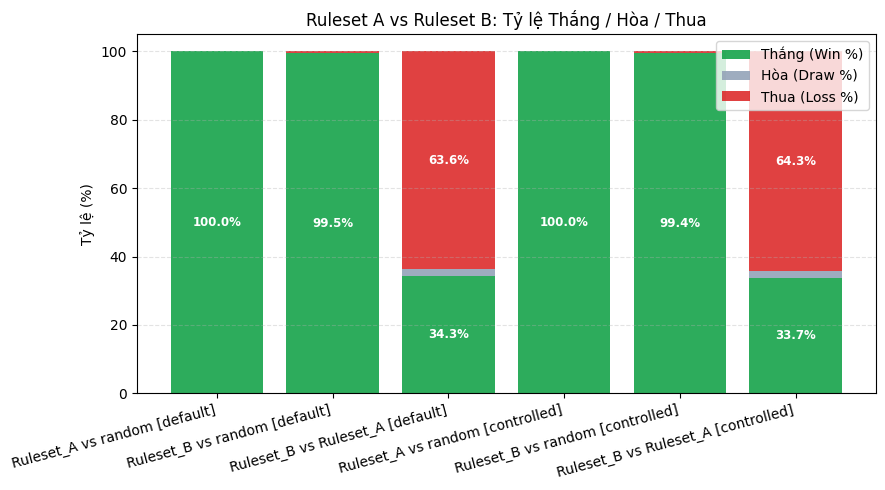

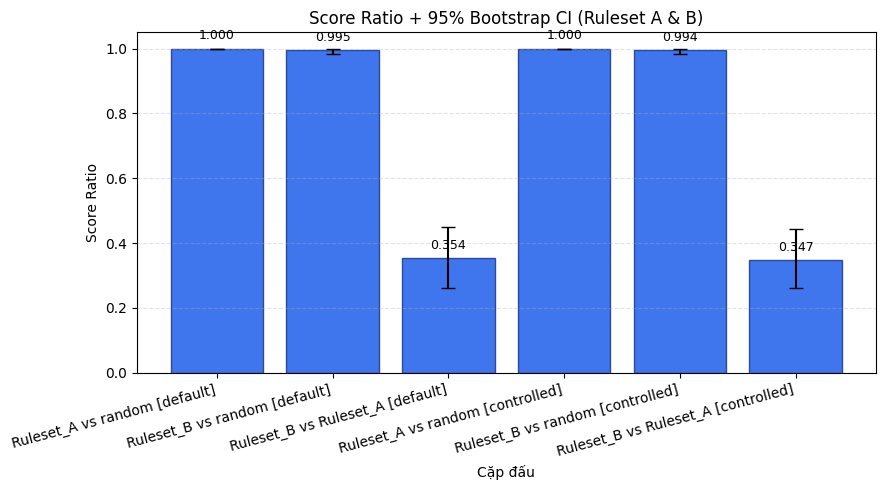

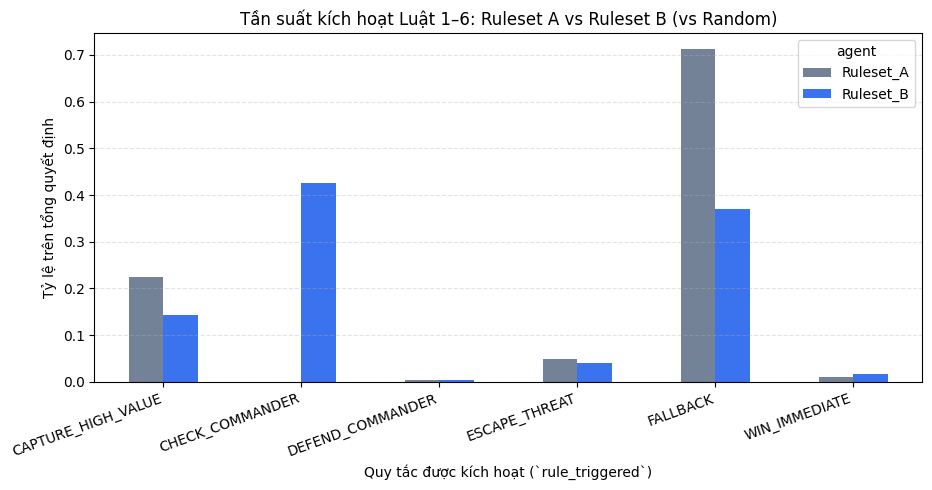

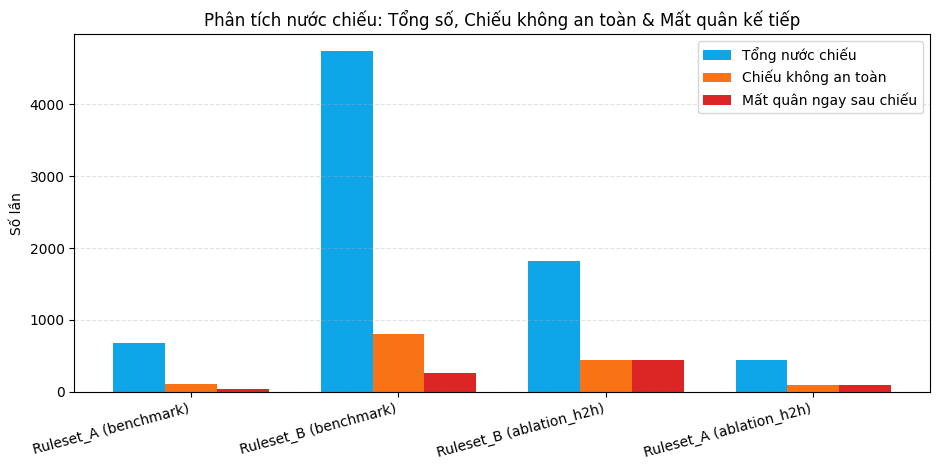

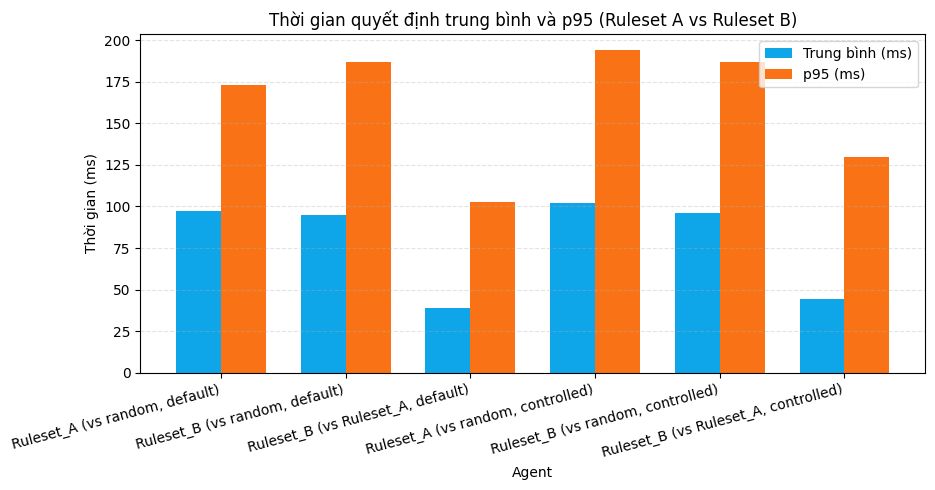

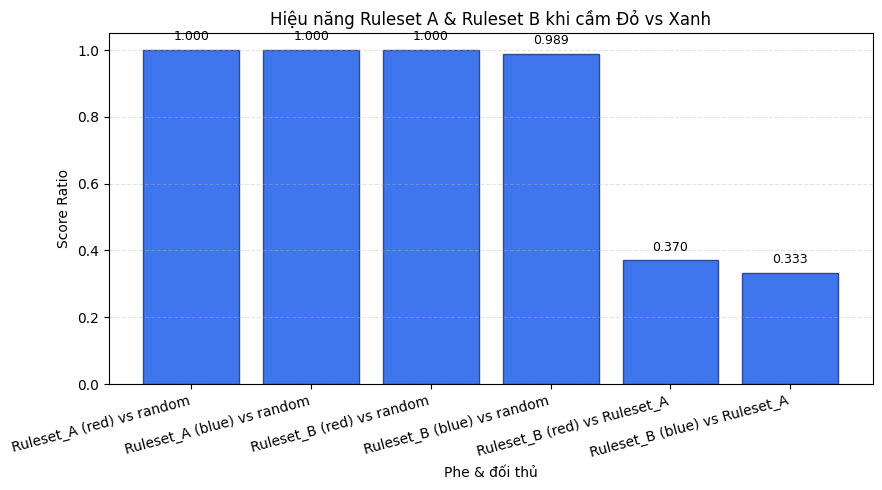

Ví dụ tình huống Ruleset A và Ruleset B chọn khác nhau:


,game_id,turn_number,state_hash,ruleset_A_action,ruleset_A_rule,ruleset_B_action,ruleset_B_rule,ruleset_B_conflicts,ruleset_B_unsafe_check
0,Ruleset_A_vs_random_g0001_s2026,47,98aa37b2153e4af1,"BOARD:red_aircraft_1@(1,2)->(3,0)#target=red_n...",FALLBACK,"MOVE:red_militia_1@(9,9)->(10,8)",CHECK_COMMANDER,[],False
1,Ruleset_A_vs_random_g0001_s2026,49,f7466fedcf48bcff,"BOARD:red_aircraft_1@(1,2)->(3,0)#target=red_n...",FALLBACK,"MOVE:red_militia_1@(9,9)->(10,8)",CHECK_COMMANDER,[],False
2,Ruleset_A_vs_random_g0001_s2026,61,a2e6893df06068de,"CAPTURE:red_artillery_2@(6,7)->(10,7)#target=b...",CAPTURE_HIGH_VALUE,"MOVE:red_artillery_2@(6,7)->(6,5)",CHECK_COMMANDER,"[CHECK_COMMANDER, CAPTURE_HIGH_VALUE]",False
3,Ruleset_A_vs_random_g0001_s2026,65,d9d2e3c6d67fa114,"CAPTURE:red_artillery_2@(10,5)->(11,5)#target=...",CAPTURE_HIGH_VALUE,"MOVE:red_aircraft_1@(1,2)->(5,6)",CHECK_COMMANDER,"[CHECK_COMMANDER, CAPTURE_HIGH_VALUE, ESCAPE_T...",False
4,Ruleset_A_vs_random_g0001_s2026,67,e0fe1492e1add79f,"BOARD:red_aircraft_1@(1,2)->(3,0)#target=red_n...",FALLBACK,"MOVE:red_aircraft_1@(1,2)->(5,2);carry=0",CHECK_COMMANDER,[],False


In [7]:
figures_dir = logger.run_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. W/D/L và Score + CI cho tất cả cặp đấu benchmark & ablation
bench_df = pair_results_df[pair_results_df["study_group"] != "stress"].copy()
bench_df["pair_label"] = bench_df["agent_a"] + " vs " + bench_df["agent_b"] + " [" + bench_df["budget_mode"] + "]"

plot_wdl_stacked_bar(
    bench_df,
    label_col="pair_label",
    win_col="win_rate_a",
    draw_col="draw_rate",
    loss_col="loss_rate_a",
    title="Ruleset A vs Ruleset B: Tỷ lệ Thắng / Hòa / Thua",
    save_path=figures_dir / "fig_01_wdl_rules.png",
)
plt.show()

plot_metric_bar(
    bench_df,
    label_col="pair_label",
    metric_col="score_a",
    ci_low_col="score_ci_low",
    ci_high_col="score_ci_high",
    title="Score Ratio + 95% Bootstrap CI (Ruleset A & B)",
    xlabel="Cặp đấu",
    ylabel="Score Ratio",
    save_path=figures_dir / "fig_02_score_ci.png",
)
plt.show()

# 2. Tần suất kích hoạt Luật 1 -> 6 cho Ruleset A vs Ruleset B trước Random
freq_bench = rule_freq_df[rule_freq_df["study_group"] == "benchmark"].copy()
if not freq_bench.empty:
    pivot_freq = freq_bench.pivot_table(index="rule_triggered", columns="agent", values="rate", fill_value=0.0)
    col_colors = ["#64748b" if "A" in str(c) else "#2563eb" for c in pivot_freq.columns]
    ax_rf = pivot_freq.plot(kind="bar", figsize=(9.5, 5.0), color=col_colors, alpha=0.9)
    ax_rf.set_title("Tần suất kích hoạt Luật 1–6: Ruleset A vs Ruleset B (vs Random)")
    ax_rf.set_xlabel("Quy tắc được kích hoạt (`rule_triggered`)")
    ax_rf.set_ylabel("Tỷ lệ trên tổng quyết định")
    ax_rf.grid(axis="y", linestyle="--", alpha=0.35)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(figures_dir / "fig_03_rule_frequency.png", dpi=150, bbox_inches="tight")
    plt.show()

# 3. Chiếu an toàn vs Chiếu không an toàn & Mất quân sau chiếu
tac_bench = tactical_summary_df[tactical_summary_df["study_group"].isin(["benchmark", "ablation_h2h"])].copy()
if not tac_bench.empty:
    tac_bench["cfg_label"] = tac_bench["agent"] + " (" + tac_bench["study_group"] + ")"
    fig_chk, ax_chk = plt.subplots(figsize=(9.5, 4.8))
    x = np.arange(len(tac_bench))
    w = 0.25
    ax_chk.bar(x - w, tac_bench["check_moves"], w, label="Tổng nước chiếu", color="#0ea5e9")
    ax_chk.bar(x, tac_bench["unsafe_check_moves"], w, label="Chiếu không an toàn", color="#f97316")
    ax_chk.bar(x + w, tac_bench["checks_followed_by_loss"], w, label="Mất quân ngay sau chiếu", color="#dc2626")
    ax_chk.set_xticks(x)
    ax_chk.set_xticklabels(tac_bench["cfg_label"], rotation=15, ha="right")
    ax_chk.set_title("Phân tích nước chiếu: Tổng số, Chiếu không an toàn & Mất quân kế tiếp")
    ax_chk.set_ylabel("Số lần")
    ax_chk.legend()
    ax_chk.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.savefig(figures_dir / "fig_04_check_safety_ablation.png", dpi=150, bbox_inches="tight")
    plt.show()

# 4. Độ trễ quyết định & So sánh Đỏ / Xanh
lat_df = pd.DataFrame([
    {"agent": f"{r['agent_a']} (vs {r['agent_b']}, {r['budget_mode']})", "avg_decision_time_ms": r["mean_decision_ms_a"], "p95_decision_time_ms": r["p95_decision_ms_a"]}
    for _, r in bench_df.iterrows()
])
plot_decision_time_comparison(
    lat_df,
    title="Thời gian quyết định trung bình và p95 (Ruleset A vs Ruleset B)",
    save_path=figures_dir / "fig_05_latency.png",
)
plt.show()

if not red_blue_df.empty:
    rb_p = red_blue_df.copy()
    rb_p["label"] = rb_p["agent"] + " (" + rb_p["side"] + ") vs " + rb_p["opponent"]
    plot_metric_bar(
        rb_p,
        label_col="label",
        metric_col="score_ratio",
        title="Hiệu năng Ruleset A & Ruleset B khi cầm Đỏ vs Xanh",
        xlabel="Phe & đối thủ",
        ylabel="Score Ratio",
        save_path=figures_dir / "fig_06_red_blue_split.png",
    )
    plt.show()

if divergent_examples:
    print("Ví dụ tình huống Ruleset A và Ruleset B chọn khác nhau:")
    display(pd.DataFrame(divergent_examples))


## VIII. Nhận xét và kết luận

*(Tổng hợp sau khi chạy thực nghiệm; mọi kết luận phải dẫn nguồn trực tiếp từ `pair_results.csv`, `rule_tactical_summary.csv` và `ablation_l3_summary.csv`)*

1. **Hiệu quả so với Random:** Đánh giá mức chênh lệch Score, Win Rate và số lượt trung bình của `Ruleset_A` và `Ruleset_B` khi đấu 200 ván với `RandomAgent`.
2. **Phân bố kích hoạt quy tắc:** Luật nào kích hoạt nhiều nhất (thường Luật 4 / Luật 6) và luật nào ít xuất hiện hơn; tỷ lệ `fallback` và `rule_conflicts`.
3. **Kết quả Ablation Luật 3 (`Ruleset_A` vs `Ruleset_B`):**
   - Bật Luật 3 có cải thiện Score đáng kể (xét cả CI của chênh lệch `score_B - score_A`) khi đối đầu với `Random` và đối đầu trực tiếp `Ruleset_B vs Ruleset_A` hay không? *(Đối chứng trực tiếp giữa `RuleBased` và `Heuristic` được thực hiện tuần tự ở notebook `09_test_heuristic_agent.ipynb`.)*
   - Tần suất `unsafe_check_moves`, `checks_followed_by_loss` và các tình huống điển hình trong `divergent_states_A_vs_B.json` cho thấy Luật 3 mang lại lợi thế áp lực hay đôi khi đánh đổi quân lực.
4. **Ổn định màu quân, seed và stress test:** Đối chiếu Đỏ/Xanh (`red_blue_splits.csv`), biến động giữa các seed và tỷ lệ `truncated` khi tự đấu (`A vs A`, `B vs B`).
5. **Quyết định cuối cùng về Ruleset chính thức:** Chọn `Ruleset_B` hay `Ruleset_A` làm baseline Rule-based chính thức cho giai đoạn sau dựa trên dữ liệu thực nghiệm.